# Model experiments

**Objective:** compare algorithms, feature sets and hyperparameters with the
**same validation framework** (5-fold grouped by location), then build the
submission.

Rules followed in this notebook:

- one validation setup for everything, so differences come from the models;
- no early stopping on the validation fold (it would leak information into the
  score), fixed number of trees instead;
- the threshold is chosen on out-of-fold predictions;
- every experiment gets an ID (`EXP-001`, ...) in `outputs/experiments_log.csv`;
- test predictions are the **average of the fold models**, which keeps the
  threshold and the test probabilities consistent.

## Imports

In [1]:
import sys
from pathlib import Path

# Make the project root importable (the notebook runs from notebooks/)
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

from src.config import ID_COL, LOCATION_COL, TARGET, TEST_MERGED, TRAIN_MERGED
from src.experiments import ExperimentLogger
from src.features import prepare_features
from src.metrics import find_best_threshold
from src.models import make_builder
from src.submission import make_submission
from src.validation import cross_validate, evaluate_oof, make_folds

pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)

## Load data and build folds

In [2]:
train = pd.read_csv(TRAIN_MERGED)
test = pd.read_csv(TEST_MERGED)

y = train[TARGET]
folds = make_folds(y, "group", groups=train[LOCATION_COL])
VALIDATION_NAME = "group_location_5fold"

# Start a clean experiment log for this run
logger = ExperimentLogger()
logger.reset()

# Every fitted candidate is stored here: name -> dict(oof, test_pred, metrics, ...)
candidates = {}

## Experiment runner

In [3]:
def run_experiment(name, feature_set="base", drop_location=True, params=None, conclusion=""):
    """Cross-validate one model, log it and keep its predictions."""
    X = prepare_features(train, feature_set, drop_location)
    X_test = prepare_features(test, feature_set, drop_location)

    result = cross_validate(make_builder(name, X, params), X, y, folds, X_test)
    metrics = evaluate_oof(y, result)

    label = feature_set + ("" if drop_location else "+location")
    exp_id = logger.log(name, label, params, VALIDATION_NAME, metrics, conclusion)

    key = f"{exp_id} {name} [{label}]"
    candidates[key] = {**result, "metrics": metrics, "model": name, "features": label}
    print(f"{exp_id} | {name:14s} | {label:18s} | AUC {metrics['ROC_AUC']:.4f} | "
          f"F1 {metrics['F1']:.4f} | score {metrics['score']:.4f}")
    return key

## A. Feature sets (CatBoost)

Does location information help, and do the derived climate features help?

In [4]:
fs_runs = {
    "base+location": run_experiment("catboost", "base", drop_location=False,
                                    conclusion="Location variables kept"),
    "base": run_experiment("catboost", "base", drop_location=True,
                           conclusion="Location variables removed"),
    "engineered": run_experiment("catboost", "engineered", drop_location=True,
                                 conclusion="Derived climate features added"),
}

fs_scores = {k: candidates[v]["metrics"]["score"] for k, v in fs_runs.items()}
best_fs_label = max(fs_scores, key=fs_scores.get)
print("\nBest feature set:", best_fs_label)

BEST_FEATURE_SET = "engineered" if best_fs_label == "engineered" else "base"
BEST_DROP_LOCATION = best_fs_label != "base+location"

EXP-001 | catboost       | base+location      | AUC 0.8065 | F1 0.8119 | score 0.8097


EXP-002 | catboost       | base               | AUC 0.8059 | F1 0.8159 | score 0.8119


EXP-003 | catboost       | engineered         | AUC 0.8066 | F1 0.8143 | score 0.8112

Best feature set: base


## B. Algorithm comparison

All algorithms use the best feature set from section A and default parameters.

In [5]:
# CatBoost with default parameters was already run in section A on this feature set
model_runs = {"catboost": fs_runs[best_fs_label]}

for model_name in ["logreg", "random_forest", "extra_trees", "lightgbm", "xgboost"]:
    model_runs[model_name] = run_experiment(
        model_name, BEST_FEATURE_SET, BEST_DROP_LOCATION, conclusion="Default parameters"
    )

EXP-004 | logreg         | base               | AUC 0.8019 | F1 0.8199 | score 0.8127


EXP-005 | random_forest  | base               | AUC 0.8092 | F1 0.8156 | score 0.8130


EXP-006 | extra_trees    | base               | AUC 0.8077 | F1 0.8153 | score 0.8123


EXP-007 | lightgbm       | base               | AUC 0.8108 | F1 0.8154 | score 0.8135


EXP-008 | xgboost        | base               | AUC 0.8110 | F1 0.8164 | score 0.8143


## C. CatBoost hyperparameters

The default configuration (depth 6, learning rate 0.03, l2 5) is already covered in section A.

In [6]:
catboost_configs = [
    {"depth": 5, "learning_rate": 0.03, "l2_leaf_reg": 5},
    {"depth": 4, "learning_rate": 0.05, "l2_leaf_reg": 3},
    {"depth": 7, "learning_rate": 0.03, "l2_leaf_reg": 8},
    {"depth": 6, "learning_rate": 0.02, "l2_leaf_reg": 10, "iterations": 900},
]

cb_runs = []
for cfg in catboost_configs:
    cb_runs.append(run_experiment(
        "catboost", BEST_FEATURE_SET, BEST_DROP_LOCATION, params=cfg,
        conclusion="Hyperparameter search",
    ))

EXP-009 | catboost       | base               | AUC 0.8092 | F1 0.8150 | score 0.8127


EXP-010 | catboost       | base               | AUC 0.8024 | F1 0.8121 | score 0.8082


EXP-011 | catboost       | base               | AUC 0.8069 | F1 0.8144 | score 0.8114


EXP-012 | catboost       | base               | AUC 0.8079 | F1 0.8160 | score 0.8127


## Experiment leaderboard

In [7]:
log = logger.load()
cols = ["exp_id", "model", "feature_set", "hyperparameters", "threshold",
        "F1", "ROC_AUC", "score", "fold_auc_std"]
log[cols].sort_values("score", ascending=False).reset_index(drop=True)

,exp_id,model,feature_set,hyperparameters,threshold,F1,ROC_AUC,score,fold_auc_std
0,EXP-008,xgboost,base,{},0.36,0.8164,0.8110,0.8143,0.0139
1,EXP-007,lightgbm,base,{},0.37,0.8154,0.8108,0.8135,0.0126
2,EXP-005,random_forest,base,{},0.41,0.8156,0.8092,0.8130,0.0097
3,EXP-004,logreg,base,{},0.30,0.8199,0.8019,0.8127,0.0165
4,EXP-012,catboost,base,"{'depth': 6, 'learning_rate': 0.02, 'l2_leaf_reg': 10, 'iterations': 900}",0.31,0.8160,0.8079,0.8127,0.0100
5,EXP-009,catboost,base,"{'depth': 5, 'learning_rate': 0.03, 'l2_leaf_reg': 5}",0.40,0.8150,0.8092,0.8127,0.0102
6,EXP-006,extra_trees,base,{},0.48,0.8153,0.8077,0.8123,0.0143
7,EXP-002,catboost,base,{},0.36,0.8159,0.8059,0.8119,0.0079
8,EXP-011,catboost,base,"{'depth': 7, 'learning_rate': 0.03, 'l2_leaf_reg': 8}",0.30,0.8144,0.8069,0.8114,0.0117
9,EXP-003,catboost,engineered,{},0.36,0.8143,0.8066,0.8112,0.0104


**How to read the leaderboard:** compare score gaps with `fold_auc_std`.
When two models differ by less than the fold-to-fold spread, treat them as a
tie rather than a real improvement, and prefer the simpler or more stable one.

## D. Feature importance (best single model)

Diagnostic only: importance is not causality, but a dominant or odd variable
is a hint to look for leakage.

Best single model: EXP-008 xgboost [base]


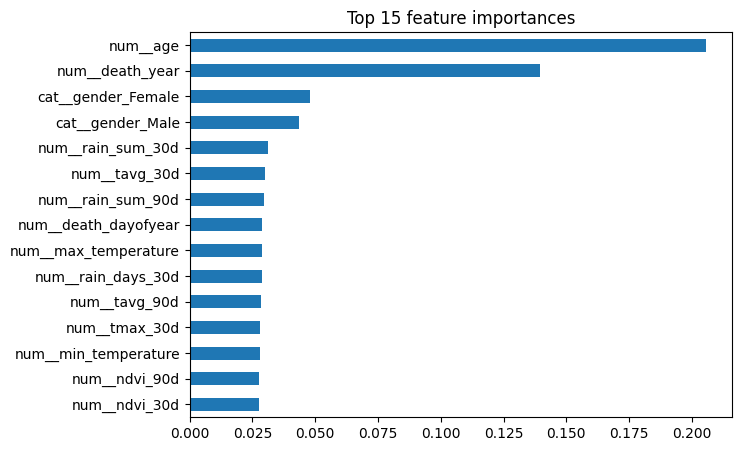

In [8]:
best_single_key = max(
    (k for k in candidates if candidates[k]["model"] != "logreg"),
    key=lambda k: candidates[k]["metrics"]["score"],
)
print("Best single model:", best_single_key)

X_full = prepare_features(train, BEST_FEATURE_SET, BEST_DROP_LOCATION)
best_model_name = candidates[best_single_key]["model"]
importance_model = make_builder(best_model_name, X_full)()
importance_model.fit(X_full, y)

if best_model_name == "catboost":
    importances = pd.Series(importance_model.get_feature_importance(), index=X_full.columns)
elif hasattr(importance_model[-1], "feature_importances_"):
    names = importance_model[0].get_feature_names_out()
    importances = pd.Series(importance_model[-1].feature_importances_, index=names)
else:
    importances = pd.Series(dtype=float)

if len(importances):
    importances.sort_values().tail(15).plot(kind="barh", figsize=(7, 5))
    plt.title("Top 15 feature importances")
    plt.show()

## E. Probability comparison and ensembles

Models with similar scores can still make different errors. The correlation
of their out-of-fold probabilities shows how much an ensemble can gain.

In [9]:
# Best configuration per algorithm
best_per_model = {}
for key, c in candidates.items():
    name = c["model"]
    if name not in best_per_model or c["metrics"]["score"] > candidates[best_per_model[name]]["metrics"]["score"]:
        best_per_model[name] = key

top_keys = sorted(best_per_model.values(), key=lambda k: -candidates[k]["metrics"]["score"])[:3]
print("Models used in the ensemble:")
for k in top_keys:
    print("  ", k)

oof_matrix = pd.DataFrame({k.split(" ")[1]: candidates[k]["oof"] for k in top_keys})
display(oof_matrix.corr().round(3))

Models used in the ensemble:
   EXP-008 xgboost [base]
   EXP-007 lightgbm [base]
   EXP-005 random_forest [base]


,xgboost,lightgbm,random_forest
xgboost,1.000,0.990,0.958
lightgbm,0.990,1.000,0.955
random_forest,0.958,0.955,1.000


In [10]:
def blend(keys, method):
    """Blend several candidates by mean probability or by mean rank."""
    oofs = np.column_stack([candidates[k]["oof"] for k in keys])
    tests = np.column_stack([candidates[k]["test_pred"] for k in keys])

    if method == "mean":
        oof, test_pred = oofs.mean(axis=1), tests.mean(axis=1)
    else:  # rank average, rescaled to [0, 1]
        oof = np.column_stack([rankdata(oofs[:, i]) / len(oofs) for i in range(oofs.shape[1])]).mean(axis=1)
        test_pred = np.column_stack([rankdata(tests[:, i]) / len(tests) for i in range(tests.shape[1])]).mean(axis=1)

    fold_auc = [roc_auc_score(y.iloc[v], oof[v]) for _, v in folds]
    result = {"oof": oof, "test_pred": test_pred, "fold_auc": fold_auc,
              "covered": np.ones(len(oof), dtype=bool)}
    return result, evaluate_oof(y, result)


for method in ["mean", "rank"]:
    result, metrics = blend(top_keys, method)
    exp_id = logger.log(
        f"ensemble_{method}", "mixed", {"members": [k.split(" ")[1] for k in top_keys]},
        VALIDATION_NAME, metrics, "Simple blend of the top 3 models",
    )
    key = f"{exp_id} ensemble_{method}"
    candidates[key] = {**result, "metrics": metrics, "model": f"ensemble_{method}", "features": "mixed"}
    print(f"{exp_id} | ensemble_{method:5s} | AUC {metrics['ROC_AUC']:.4f} | "
          f"F1 {metrics['F1']:.4f} | score {metrics['score']:.4f}")

EXP-013 | ensemble_mean  | AUC 0.8123 | F1 0.8166 | score 0.8149


EXP-014 | ensemble_rank  | AUC 0.8126 | F1 0.8161 | score 0.8147


## F. Final choice and submission

The final candidate is the best score among all experiments. Note that picking
the maximum over many candidates is slightly optimistic. Rank blends are
excluded from the final choice because their test scores are rescaled by rank,
which does not match the threshold learned on the out-of-fold ranks as well as
probabilities do.

In [11]:
eligible = {k: c for k, c in candidates.items() if "ensemble_rank" not in k}
final_key = max(eligible, key=lambda k: eligible[k]["metrics"]["score"])
final = candidates[final_key]

print("Final candidate:", final_key)
print({k: round(v, 4) for k, v in final["metrics"].items() if k not in ("table", "n_scored")})

mask = final["covered"]
best_threshold, threshold_table = find_best_threshold(y[mask], final["oof"][mask])
print("\nThreshold used:", best_threshold["threshold"])

Final candidate: EXP-013 ensemble_mean
{'threshold': 0.39, 'F1': 0.8166, 'ROC_AUC': 0.8123, 'score': 0.8149, 'score_at_0.5': 0.8066, 'fold_auc_mean': 0.8131, 'fold_auc_std': 0.0116}



Threshold used: 0.39


In [12]:
submission, path = make_submission(
    ids=test[ID_COL],
    test_prob=final["test_pred"],
    threshold=best_threshold["threshold"],
    filename="submission_v1.csv",
)

print("Saved to:", path)
print("Shape:", submission.shape)
print("\nPredicted label distribution (test):")
print(submission["TargetF1"].value_counts(normalize=True).round(3))
print("\nTrain positive rate:", round(y.mean(), 3))
print("\nProbability summary:")
print(submission["TargetRAUC"].describe().round(3))
submission.head()

Saved to: /home/claude/proj/outputs/submissions/submission_v1.csv
Shape: (1030, 3)

Predicted label distribution (test):
TargetF1
1    0.82
0    0.18
Name: proportion, dtype: float64

Train positive rate: 0.651

Probability summary:
count    1030.000
mean        0.655
std         0.241
min         0.139
25%         0.450
50%         0.661
75%         0.897
max         0.978
Name: TargetRAUC, dtype: float64


,ID,TargetF1,TargetRAUC
0,ID_E760D84B,0,0.359172
1,ID_6EDEA907,1,0.724625
2,ID_B9FFC8D8,1,0.526333
3,ID_74C6C94E,1,0.442747
4,ID_0E02825D,1,0.765017
